In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

 # Q3).  Dataset Preparation and Graph Construction

## a) Data Extraction and Resampling

In [9]:
import numpy as np, pandas as pd


In [2]:
import numpy as np, pandas as pd, h5py, time, random, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = "/kaggle/working"
D = "/kaggle/input/datasets/liuxu77/largest"
meta = pd.read_csv(f"{D}/ca_meta.csv")
meta.head()

,ID,Lat,Lng,District,County,Fwy,Lanes,Type,Direction,ID2
0,317802,38.389811,-121.479587,3,Sacramento,I5-N,2,Mainline,N,0
1,312134,38.412564,-121.484319,3,Sacramento,I5-N,2,Mainline,N,1
2,312133,38.428630,-121.487657,3,Sacramento,I5-N,3,Mainline,N,2
3,313159,38.450246,-121.492176,3,Sacramento,I5-N,3,Mainline,N,3
4,319767,38.465539,-121.496450,3,Sacramento,I5-N,3,Mainline,N,4


In [6]:
meta.describe()

,ID,Lat,Lng,District,Lanes,ID2
count,8.600000e+03,8600.000000,8600.000000,8600.000000,8600.000000,8600.000000
mean,1.320325e+07,35.574187,-119.531740,7.039302,3.627674,4299.500000
std,7.743700e+07,2.012747,2.022292,2.876953,1.069066,2482.750491
min,3.085110e+05,32.544296,-123.029949,3.000000,1.000000,0.000000
25%,4.045598e+05,33.891151,-121.781454,4.000000,3.000000,2149.750000
50%,7.611345e+05,34.276766,-118.509098,7.000000,4.000000,4299.500000
75%,1.077735e+06,37.702405,-117.763161,10.000000,4.000000,6449.250000
max,5.068001e+08,39.422496,-114.559672,12.000000,8.000000,8599.000000


In [8]:
meta.shape

(8600, 10)

In [14]:
(meta["County"]=="San Diego").value_counts()

County
False    7884
True      716
Name: count, dtype: int64

In [4]:
sd_mask = (meta["District"] == 11).values
sd_ids  = meta.loc[sd_mask, "ID"].astype(str).tolist()
sd_idx  = meta.loc[sd_mask, "ID2"].values.astype(int)    
assert len(sd_ids) == 716
assert (meta["ID2"].values == np.arange(len(meta))).all()
print(meta.loc[sd_mask, "County"].value_counts())
A = np.load(f"{D}/ca_rn_adj.npy", mmap_mode="r")[np.ix_(sd_idx, sd_idx)].astype(np.float32)
print("A:", A.shape)

County
San Diego    716
Name: count, dtype: int64
A: (716, 716)


In [5]:
def load_sd(year):
    with h5py.File(f"{D}/ca_his_raw_{year}.h5", "r") as f:
        g = f["t"]
        cols = [c.decode() for c in g["block0_items"][:]]
        times = pd.to_datetime(g["axis1"][:])
        pos = {c: i for i, c in enumerate(cols)}
        sel = np.array([pos[s] for s in sd_ids])
        order = np.argsort(sel); back = np.argsort(order)      
        vals = g["block0_values"]
        out = np.empty((len(times), len(sd_ids)), np.float32)
        for i in range(0, len(times), 8192):
            out[i:i+8192] = vals[i:i+8192, :][:, sel[order]][:, back]
    return pd.DataFrame(out, index=times, columns=sd_ids)

In [6]:

t0 = time.time()
raw = pd.concat([load_sd(2020), load_sd(2021)])
print(raw.shape, raw.index.min(), raw.index.max(), f"{time.time()-t0:.0f}s")
print("NaN frac:", raw.isna().mean().mean(), "| zero frac:", (raw == 0).mean().mean())
raw.to_pickle(f"{OUT}/sd_raw_5min.pkl"); np.save(f"{OUT}/A_sd.npy", A)   #

(210528, 716) 2020-01-01 00:00:00 2021-12-31 23:55:00 65s
NaN frac: 0.050661834230465816 | zero frac: 0.002666997518768453


In [10]:
OUT = "/kaggle/working"
raw = pd.read_pickle(f"{OUT}/sd_raw_5min.pkl")
A = np.load(f"{OUT}/A_sd.npy")
meta = pd.read_csv("/kaggle/input/datasets/liuxu77/largest/ca_meta.csv")
sd_ids = list(raw.columns)

In [13]:
print("shape ", raw.shape)
print(raw.index.min())
print(raw.index.max())

shape  (210528, 716)
2020-01-01 00:00:00
2021-12-31 23:55:00


In [16]:
X15 = raw.resample("15min").sum(min_count=3)   
X15.shape

(70176, 716)

In [28]:
X15.isna().sum()

1114091       13
1118333       12
1118348       12
1114720        9
1118352       10
           ...  
1123276       12
1122394    43878
1123261       12
1123256    43878
1122412       12
Length: 716, dtype: int64

Handling missing values: 

linear interpolation if the gap is <=  2 steps (i.e. 30 minutes) (Mallek et al. (2022); Shafique (2022))

time-of-day averages for > 2 : separated by weekdays and weekends under the assumption that traffic can be generalised (Mallek et al. (2022)) 

training data mean for the remaining with no available data (Jiang et al. (2025); Kong et al. (2023)) 

In [121]:
import numpy as np
import pandas as pd

def nan_run_lengths(s: pd.Series) -> pd.Series:
    """For each NaN, the length of the consecutive NaN run it belongs to (0 for observed)."""
    isna = s.isna()
    grp = (~isna).cumsum()
    run = isna.groupby(grp).transform("sum")
    return run.where(isna, 0)

def fill_missing(X: pd.DataFrame, train_mask, max_gap: int = 2):
    """
    Tiered imputation. X: DataFrame (DatetimeIndex @15min, columns = sensors).
    train_mask: boolean array/Series, True for training rows (2020).
    Returns (X_filled, missing_mask, stats).
    """
    missing = X.isna()
    train_mask = np.asarray(train_mask)

    # Tier 1: linear interpolation for short interior gaps
    run = X.apply(nan_run_lengths)
    splits = [("2020-01-01", "2020-12-31"), ("2021-01-01", "2021-03-31"), ("2021-04-01", "2021-12-31")]
    interp = pd.concat([X.loc[a:b].interpolate(method="linear", limit_area="inside") for a, b in splits])    
    short = missing & (run <= max_gap) & interp.notna()
    out = X.where(~short, interp)
    n_short = int(short.values.sum())

    # Tier 2: time-of-day mean, weekday vs weekend, from TRAIN observed values only
    idx = X.index
    is_wkend = idx.dayofweek >= 5
    slot = idx.hour * 4 + idx.minute // 15
    train_obs = X[train_mask]
    profile = train_obs.groupby([is_wkend[train_mask], slot[train_mask]]).mean()
    keys = pd.MultiIndex.from_arrays([is_wkend, slot])
    prof_full = pd.DataFrame(profile.reindex(keys).values, index=idx, columns=X.columns)
    before = int(out.isna().values.sum())
    out = out.fillna(prof_full)
    n_profile = before - int(out.isna().values.sum())

    # Tier 3: per-sensor training mean, then global training mean as a last resort
    sensor_mean = train_obs.mean()
    before = int(out.isna().values.sum())
    out = out.fillna(sensor_mean).fillna(float(sensor_mean.mean()))
    n_mean = before - int(out.isna().values.sum())

    assert not out.isna().any().any()
    total = int(missing.values.sum())
    stats = dict(total_missing=total,
                 pct_missing=100 * total / missing.size,
                 interpolated=n_short, time_of_day=n_profile, train_mean=n_mean)
    return out, missing, stats

# usage
train_mask = (X15.index.year == 2020)
X15_filled, miss_mask, stats = fill_missing(X15, train_mask, max_gap=2)
print(stats)
np.save(f"{OUT}/missing_mask.npy", miss_mask.values)   # use this to mask loss/metrics

{'total_missing': 2550289, 'pct_missing': 5.075604402148023, 'interpolated': 4970, 'time_of_day': 1211975, 'train_mean': 1333344}


In [44]:
X15

,1114091,1118333,1118348,1114720,1118352,1118743,1120362,1118796,1118735,1118450,...,1125829,1125348,1125353,1125359,1123287,1123276,1122394,1123261,1123256,1122412
2020-01-01 00:00:00,168.0,94.0,83.0,112.0,96.0,220.0,267.0,161.0,174.0,180.0,...,81.0,81.0,81.0,152.0,29.0,104.0,26.0,22.0,60.0,101.0
2020-01-01 00:15:00,179.0,82.0,66.0,116.0,122.0,323.0,458.0,308.0,339.0,316.0,...,81.0,80.0,84.0,180.0,38.0,113.0,27.0,23.0,73.0,105.0
2020-01-01 00:30:00,242.0,106.0,76.0,141.0,131.0,403.0,481.0,324.0,370.0,364.0,...,80.0,69.0,72.0,137.0,30.0,109.0,23.0,20.0,61.0,98.0
2020-01-01 00:45:00,280.0,139.0,97.0,144.0,160.0,414.0,476.0,360.0,387.0,383.0,...,70.0,62.0,69.0,155.0,44.0,119.0,40.0,37.0,71.0,112.0
2020-01-01 01:00:00,276.0,133.0,105.0,146.0,142.0,382.0,443.0,310.0,338.0,347.0,...,69.0,70.0,71.0,150.0,50.0,127.0,43.0,44.0,82.0,134.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-12-31 22:45:00,123.0,49.0,67.0,129.0,179.0,288.0,371.0,419.0,306.0,333.0,...,NaN,105.0,110.0,182.0,41.0,120.0,NaN,33.0,NaN,100.0
2021-12-31 23:00:00,152.0,68.0,70.0,145.0,179.0,280.0,376.0,416.0,275.0,341.0,...,NaN,132.0,135.0,231.0,48.0,118.0,NaN,30.0,NaN,110.0
2021-12-31 23:15:00,160.0,75.0,85.0,166.0,176.0,287.0,360.0,353.0,261.0,281.0,...,NaN,115.0,117.0,208.0,53.0,133.0,NaN,37.0,NaN,126.0
2021-12-31 23:30:00,142.0,67.0,73.0,143.0,176.0,259.0,358.0,348.0,224.0,264.0,...,NaN,120.0,122.0,206.0,54.0,128.0,NaN,40.0,NaN,132.0


### one week plot with missing values

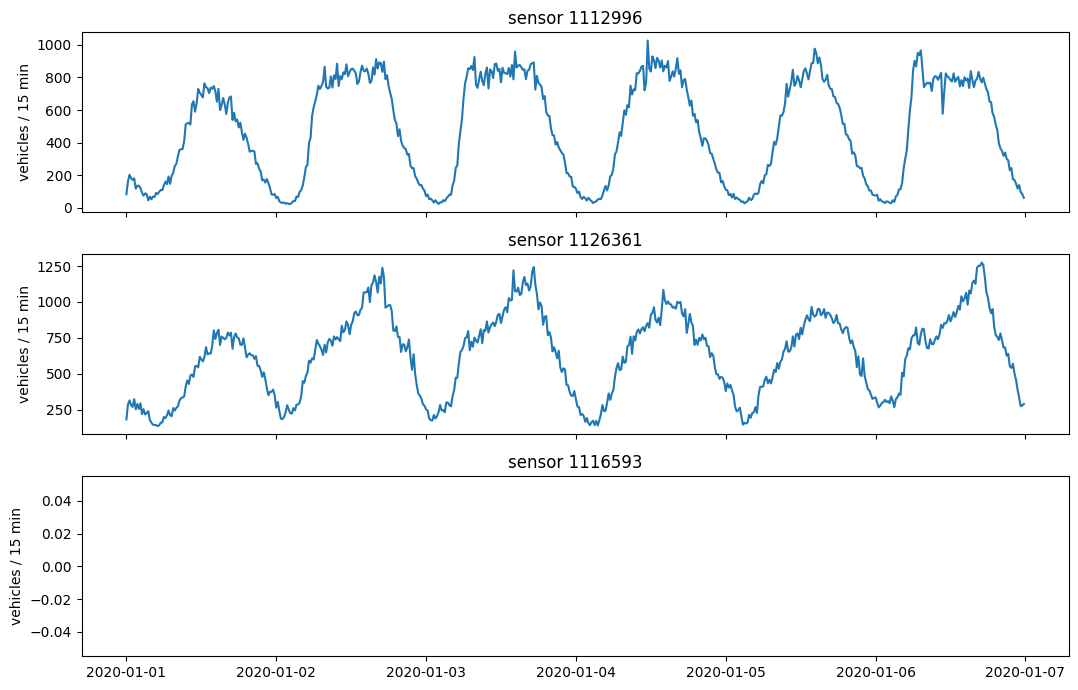

In [58]:
import matplotlib.pyplot as plt
week = X15["2020-01-01":"2020-01-06"]            
chosen = list(week.isna().mean().sort_values().index[[0, 350, 712 ]])  
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a, s in zip(ax, chosen):
    a.plot(week.index, week[s]); a.set_title(f"sensor {s}"); a.set_ylabel("vehicles / 15 min")
plt.tight_layout(); plt.savefig(f"{OUT}/q3a_week.png", dpi=150); plt.show()

#### one week plot after handling missing values 

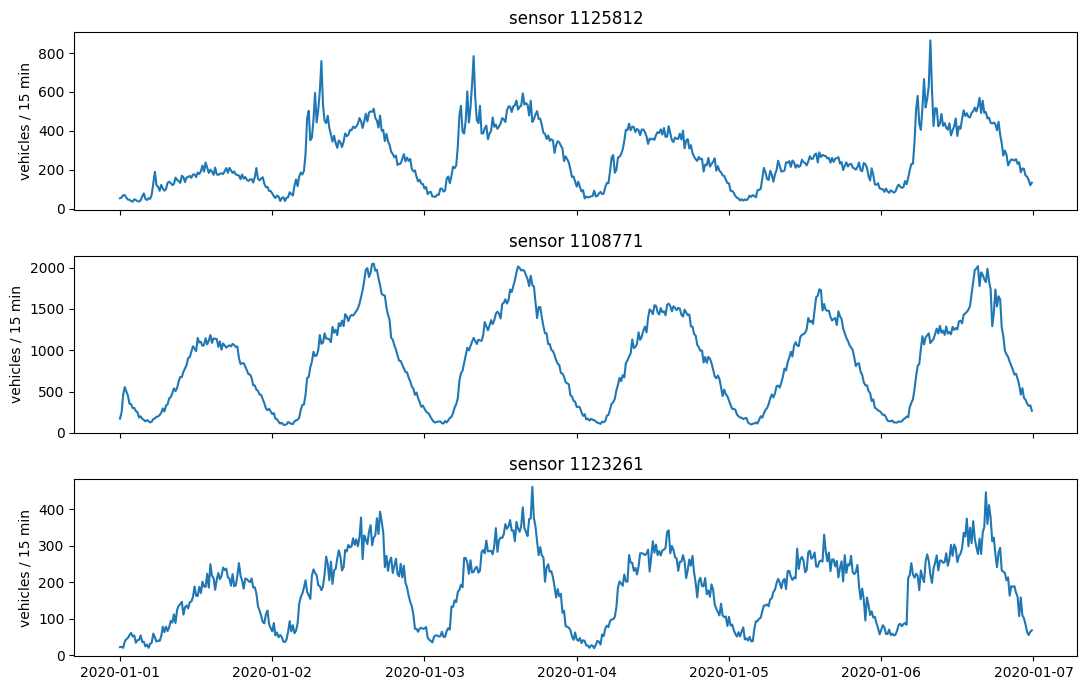

In [59]:
import matplotlib.pyplot as plt
week = X15_filled["2020-01-01":"2020-01-06"]            
chosen = list(week.isna().mean().sort_values().index[[0, 350, 712 ]])  
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a, s in zip(ax, chosen):
    a.plot(week.index, week[s]); a.set_title(f"sensor {s}"); a.set_ylabel("vehicles / 15 min")
plt.tight_layout(); plt.savefig(f"{OUT}/q3a_week.png", dpi=150); plt.show()

In [48]:
X15["1116593"].mean()

nan

## Q3(b)

In [62]:
nz = A != 0
off = nz & ~np.eye(716, dtype=bool)                      
print("nodes:", A.shape[0])
print("nonzero entries (incl. diagonal):", int(nz.sum()), "| off-diagonal edges:", int(off.sum()))
print("diagonal nonzero:", int(np.diag(nz).sum()))


nodes: 716
nonzero entries (incl. diagonal): 18035 | off-diagonal edges: 17319
diagonal nonzero: 716


In [63]:

print("symmetric (values):", np.allclose(A, A.T), "| symmetric (pattern):", bool((nz == nz.T).all()))


symmetric (values): False | symmetric (pattern): False


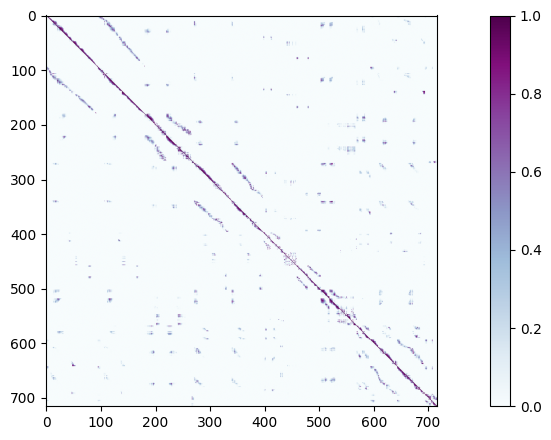

In [75]:
fig, ax = plt.subplots(1, 1, figsize=(11, 4.5))
im = ax.imshow(A, cmap="BuPu")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(f"{OUT}/q3b_adj.png", dpi=150)
plt.show()

In [64]:
print("weight range (nonzero):", A[nz].min(), A[nz].max(), "| negatives:", int((A < 0).sum()))

weight range (nonzero): 0.010001835 1.0 | negatives: 0


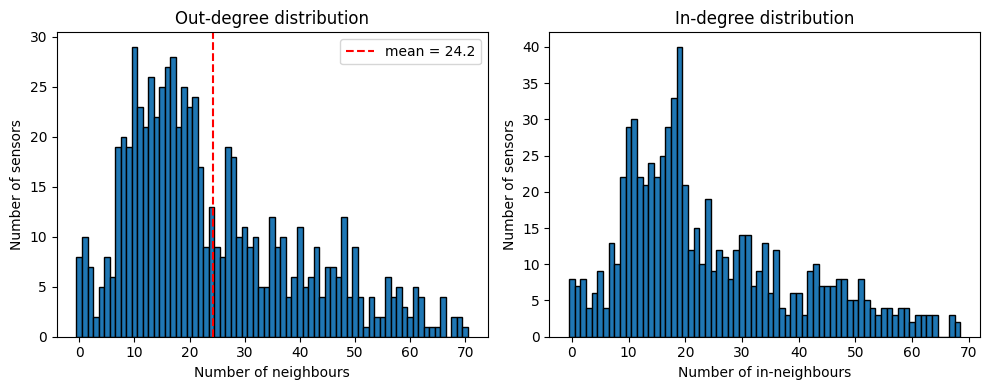

Median out-degree: 20.0 in-degree: 19.0


In [86]:
import numpy as np
import matplotlib.pyplot as plt

def neighbor_counts(A):
    """One-hop neighbour counts, excluding self-loops.
    out_deg[i] = #{j: A[i,j] != 0}, in_deg[i] = #{j: A[j,i] != 0}."""
    B = (np.asarray(A) != 0)
    np.fill_diagonal(B, False)
    return B.sum(axis=1), B.sum(axis=0)

out_deg, in_deg = neighbor_counts(A)
median_out_degree = np.median(out_deg)
median_in = np.median(in_deg)

sym = np.allclose(A, A.T)
deg = out_deg if sym else out_deg   # if symmetric, in == out

fig, ax = plt.subplots(1, 2 if not sym else 1, figsize=(10 if not sym else 5.5, 4))
ax = np.atleast_1d(ax)
bins = np.arange(deg.min(), deg.max() + 2) - 0.5
ax[0].hist(out_deg, bins=bins, edgecolor="k")
ax[0].axvline(out_deg.mean(), color="r", ls="--", label=f"mean = {out_deg.mean():.1f}")
ax[0].set(xlabel="Number of neighbours", ylabel="Number of sensors",
          title="Out-degree distribution" if not sym else "Neighbour-count distribution")
ax[0].legend()
if not sym:
    ax[1].hist(in_deg, bins=np.arange(in_deg.min(), in_deg.max() + 2) - 0.5, edgecolor="k")
    ax[1].set(xlabel="Number of in-neighbours", ylabel="Number of sensors",
              title="In-degree distribution")

plt.tight_layout(); plt.savefig("neighbor_distribution.png", dpi=200); plt.show()


print("Median out-degree:", median_out_degree, "in-degree:", median_in)


 Explain what a nonzero entry Aij represents

nonzero Aij represents an edge in the graph; the two nodes i,j are connected

## Q3 c

In [87]:
out_deg = off.sum(1)
print("median out-degree:", np.median(out_deg))
i = 19
print("sensor", sd_ids[i], "| out-degree", out_deg[i])
meta_sd = meta.loc[sd_mask].reset_index(drop=True)      
print(meta_sd.loc[i, ["ID", "Fwy", "Direction", "Lanes", "Type", "Lat", "Lng"]])

median out-degree: 20.0
sensor 1117782 | out-degree 41
ID              1117782
Fwy                I5-N
Direction             N
Lanes                 5
Type           Mainline
Lat           32.706216
Lng         -117.147448
Name: 19, dtype: object


In [89]:
Ai = off.astype(int)                                     
one = np.where(Ai[i])[0]                                 
via2 = np.where((Ai @ Ai)[i] > 0)[0]                     
within2 = np.setdiff1d(np.union1d(one, via2), [i])       
two_only = np.setdiff1d(within2, one)                   
print("one-hop:", len(one), "\n two-hop:", len(two_only), "\n within two hops:", len(within2))
print("one-hop freeways:\n", meta_sd.loc[one, "Fwy"].value_counts().to_string())
print("two-hop-only freeways:\n", meta_sd.loc[two_only, "Fwy"].value_counts().to_string())

one-hop: 41 
 two-hop: 78 
 within two hops: 119
one-hop freeways:
 Fwy
I5-N      12
I5-S      12
SR94-W     6
SR94-E     6
I15-N      3
I15-S      2
two-hop-only freeways:
 Fwy
I805-S     13
I5-N        9
I805-N      9
I5-S        7
I8-W        7
I8-E        7
I15-N       5
I15-S       5
SR94-W      5
SR94-E      5
SR163-S     5
SR163-N     1


# Q4

## Q4 a

In [93]:
import torch, time, random
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
DEV

'cuda'

In [94]:

splits = {"train": ("2020-01-01", "2020-12-31"),
          "val":   ("2021-01-01", "2021-03-31"),
          "test":  ("2021-04-01", "2021-12-31")}

In [98]:
tr_obs = X15.loc[splits["train"][0]:splits["train"][1]].values
mu, sd = float(np.nanmean(tr_obs)), float(np.nanstd(tr_obs))
H, FH = 8, 4


In [99]:
def make_split(x, m):
    x = torch.tensor(x, dtype=torch.float32, device=DEV)
    m = torch.tensor(m, dtype=torch.bool, device=DEV)
    n = len(x) - H - FH + 1
    xo = torch.arange(-(H - 1), 1, device=DEV)
    yo = torch.arange(1, FH + 1, device=DEV)
    return x, m, n, xo, yo


def make_batch(split, i):
    x, m, n, xo, yo = split

    t = (i + H - 1)[:, None]

    return (
        x[t + xo],
        x[t + yo],
        m[t + yo]
    )

In [101]:
S = {}

for k, (a, b) in splits.items():
    xf = (X15_filled.loc[a:b].values - mu) / sd
    mk = ~X15.loc[a:b].isna().values

    S[k] = make_split(xf, mk)

print({k: s[2] for k, s in S.items()})

{'train': 35125, 'val': 8629, 'test': 26389}


## Q4 b

### temporal encoder 

In [102]:
import torch.nn as nn, torch.nn.functional as F


In [117]:
class TemporalEnc(nn.Module):
    def __init__(s, d=16, k=2, dils=(1, 2, 4)):
        super().__init__(); s.k, s.dils = k, dils
        s.inp = nn.Conv1d(1, d, 1)
        s.convs = nn.ModuleList([nn.Conv1d(d, d, k, dilation=r) for r in dils])
    def forward(s, x):                                       
        B, T, N = x.shape
        h = s.inp(x.permute(0, 2, 1).reshape(B*N, 1, T))     
        for r, c in zip(s.dils, s.convs):
            h = F.relu(c(F.pad(h, ((s.k-1)*r, 0))))          
        return h[..., -1].view(B, N, -1)                     


In [118]:
class STGNN(nn.Module):
    def __init__(s, d=16, use_graph=True, A_hat=None):
        super().__init__()
        s.enc = TemporalEnc(d)
        s.use_graph = use_graph
        if use_graph:
            s.W = nn.Linear(d, d, bias=False)
            s.register_buffer("A_hat", A_hat)
        s.head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, FH))
    def forward(s, x):
        h = s.enc(x)                                         
        if s.use_graph:
            h = F.relu(s.A_hat @ s.W(h))                     
        return s.head(h).permute(0, 2, 1)

In [113]:
torch.backends.cudnn.benchmark = True
BS, EPOCHS, PATIENCE, LR = 64, 40, 6, 1e-3

def evaluate(model, sp, bs=256):
    model.eval(); ae = se = cnt = 0.0
    ae_h = torch.zeros(FH, dtype=torch.float64, device=DEV); n_h = torch.zeros(FH, dtype=torch.float64, device=DEV)
    with torch.no_grad():
        for i in range(0, sp.n, bs):
            x, y, m = sp.batch(torch.arange(i, min(i+bs, sp.n), device=DEV))
            err = ((model(x) - y) * sd).double(); mf = m.double()      # back to vehicles / 15 min
            ae += (err.abs()*mf).sum().item(); se += ((err**2)*mf).sum().item(); cnt += mf.sum().item()
            ae_h += (err.abs()*mf).sum((0, 2)); n_h += mf.sum((0, 2))
    return dict(mae=ae/cnt, rmse=(se/cnt)**0.5, mae_by_horizon=(ae_h/n_h).tolist())

def train(name, **kw):
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    model = STGNN(**kw).to(DEV)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(SEED)
    best, bad, best_state = 1e18, 0, None
    if DEV == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(S["train"].n, generator=g).to(DEV)
        for i in range(0, len(perm), BS):
            x, y, m = S["train"].batch(perm[i:i+BS]); mf = m.float()
            loss = ((model(x) - y).abs() * mf).sum() / mf.sum().clamp(min=1)   # masked L1
            opt.zero_grad(); loss.backward(); opt.step()
        v = evaluate(model, S["val"])
        print(f"{name} ep{ep+1:02d} val MAE {v['mae']:.2f} RMSE {v['rmse']:.2f}", flush=True)
        if v["mae"] < best - 1e-3:
            best, bad, best_state = v["mae"], 0, {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    if DEV == "cuda": torch.cuda.synchronize()
    tt = time.time() - t0
    model.load_state_dict(best_state)                                          # best validation epoch
    res = dict(name=name, epochs=ep+1, train_time_s=tt, val=evaluate(model, S["val"]), test=evaluate(model, S["test"]))
    torch.save(model.state_dict(), f"{OUT}/model_{name}.pt")
    return res

In [115]:

At = torch.tensor(A, dtype=torch.float32, device=DEV)
A_fixed = At / At.sum(1, keepdim=True)

In [120]:
print(type(S), list(S.keys()) if isinstance(S, dict) else "")
print(type(S["train"]), [type(v) for v in S["train"]] if isinstance(S["train"], tuple) else "")

<class 'dict'> ['train', 'val', 'test']
<class 'tuple'> [<class 'torch.Tensor'>, <class 'torch.Tensor'>, <class 'int'>, <class 'torch.Tensor'>, <class 'torch.Tensor'>]


In [ ]:
H, FH = 8, 4
class Split:
    def __init__(s, x, m):                       
        s.x = torch.tensor(x, dtype=torch.float32, device=DEV)
        s.m = torch.tensor(m, dtype=torch.bool, device=DEV)
        s.n = len(x) - H - FH + 1                # windows built inside the split only
        s.xo = torch.arange(-(H-1), 1, device=DEV); s.yo = torch.arange(1, FH+1, device=DEV)
    def batch(s, i):
        t = (i + H - 1)[:, None]
        return s.x[t + s.xo], s.x[t + s.yo], s.m[t + s.yo]   

S = {}
for k, (a, b) in splits.items():
    xf = (X15_filled.loc[a:b].values - mu) / sd
    mk = ~X15.loc[a:b].isna().values             # True = real measurement
    S[k] = Split(xf, mk)
print({k: type(v).__name__ for k, v in S.items()}, {k: v.n for k, v in S.items()})
# expect: Split for all three, and 35125, 8629, 26389

{'train': 'Split', 'val': 'Split', 'test': 'Split'} {'train': 35125, 'val': 8629, 'test': 26389}


In [126]:
SP = {}
for k, (a, b) in splits.items():
    xf = (X15_filled.loc[a:b].values - mu) / sd
    mk = ~X15.loc[a:b].isna().values
    SP[k] = Split(xf, mk)
print({k: type(v).__name__ for k, v in SP.items()}, {k: v.n for k, v in SP.items()})


{'train': 'Split', 'val': 'Split', 'test': 'Split'} {'train': 35125, 'val': 8629, 'test': 26389}


In [129]:
import json
results = {}
results["fixed"] = train("fixed", d=32, use_graph=True, A_hat=A_fixed)
json.dump(results, open(f"{OUT}/results.json", "w"), indent=1)
print(results["fixed"]["val"], results["fixed"]["test"])

fixed ep01 val MAE 140.57 RMSE 212.20
fixed ep02 val MAE 139.99 RMSE 212.29
fixed ep03 val MAE 139.76 RMSE 212.53
fixed ep04 val MAE 138.52 RMSE 210.96
fixed ep05 val MAE 138.20 RMSE 209.87
fixed ep06 val MAE 137.23 RMSE 209.60
fixed ep07 val MAE 135.62 RMSE 207.49
fixed ep08 val MAE 132.65 RMSE 206.51
fixed ep09 val MAE 130.40 RMSE 205.25
fixed ep10 val MAE 129.49 RMSE 204.97
fixed ep11 val MAE 129.31 RMSE 204.57
fixed ep12 val MAE 128.62 RMSE 203.72
fixed ep13 val MAE 127.96 RMSE 203.88
fixed ep14 val MAE 127.72 RMSE 204.00
fixed ep15 val MAE 127.49 RMSE 203.58
fixed ep16 val MAE 127.16 RMSE 203.53
fixed ep17 val MAE 126.89 RMSE 202.98
fixed ep18 val MAE 126.71 RMSE 203.25
fixed ep19 val MAE 126.33 RMSE 202.72
fixed ep20 val MAE 127.33 RMSE 203.80
fixed ep21 val MAE 126.16 RMSE 202.12
fixed ep22 val MAE 126.61 RMSE 201.70
fixed ep23 val MAE 125.90 RMSE 202.79
fixed ep24 val MAE 125.51 RMSE 202.77
fixed ep25 val MAE 125.41 RMSE 202.40
fixed ep26 val MAE 125.41 RMSE 201.80
fixed ep27 v

In [ ]:
class STGNN(nn.Module):
    def __init__(s, d=32, use_graph=True, A_hat=None, graph="fixed", N=716, de=10, k=20):
        super().__init__()
        s.graph, s.k = graph, k
        s.enc = TemporalEnc(d)
        s.use_graph = use_graph
        if use_graph:
            s.W = nn.Linear(d, d, bias=False)
            if graph in ("fixed", "hybrid"): s.register_buffer("A_hat", A_hat)
        s.head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, FH))
        if use_graph and graph in ("adaptive", "hybrid"):       
            s.E1 = nn.Parameter(torch.randn(N, de) * 0.1)
            s.E2 = nn.Parameter(torch.randn(N, de) * 0.1)
        if use_graph and graph == "hybrid":
            s.alpha = nn.Parameter(torch.zeros(1))             

    def scores(s):
        return F.relu(s.E1 @ s.E2.T)

    def adaptive(s):
        Sc = s.scores()
        v, i = Sc.topk(s.k, dim=-1)                              
        Sc = torch.full_like(Sc, float("-inf")).scatter(-1, i, v)
        return F.softmax(Sc, dim=-1)                            

    def forward(s, x):
        h = s.enc(x)
        if s.use_graph:
            if s.graph == "fixed": A_ = s.A_hat
            elif s.graph == "adaptive": A_ = s.adaptive()
            else:
                a = torch.sigmoid(s.alpha); A_ = a * s.A_hat + (1 - a) * s.adaptive()
            h = F.relu(A_ @ s.W(h))
        return s.head(h).permute(0, 2, 1)

In [131]:
import json, os
rp = f"{OUT}/results.json"
results = json.load(open(rp)) if os.path.exists(rp) else {}
print(list(results))      # should contain "fixed"

['fixed']


In [132]:
results["temporal"] = train("temporal", d=32, use_graph=False)
json.dump(results, open(rp, "w"), indent=1); print(results["temporal"]["test"])

temporal ep01 val MAE 60.56 RMSE 97.82
temporal ep02 val MAE 61.27 RMSE 97.78
temporal ep03 val MAE 59.46 RMSE 95.96
temporal ep04 val MAE 60.95 RMSE 97.48
temporal ep05 val MAE 59.08 RMSE 94.91
temporal ep06 val MAE 58.78 RMSE 94.15
temporal ep07 val MAE 58.09 RMSE 93.51
temporal ep08 val MAE 58.28 RMSE 93.59
temporal ep09 val MAE 58.14 RMSE 93.50
temporal ep10 val MAE 58.81 RMSE 93.62
temporal ep11 val MAE 58.56 RMSE 93.78
temporal ep12 val MAE 58.43 RMSE 94.27
temporal ep13 val MAE 57.55 RMSE 92.46
temporal ep14 val MAE 57.77 RMSE 92.38
temporal ep15 val MAE 58.00 RMSE 93.15
temporal ep16 val MAE 57.61 RMSE 92.90
temporal ep17 val MAE 57.11 RMSE 91.88
temporal ep18 val MAE 57.16 RMSE 92.00
temporal ep19 val MAE 57.24 RMSE 91.95
temporal ep20 val MAE 58.09 RMSE 93.08
temporal ep21 val MAE 57.16 RMSE 91.80
temporal ep22 val MAE 56.82 RMSE 91.34
temporal ep23 val MAE 57.36 RMSE 91.61
temporal ep24 val MAE 56.95 RMSE 91.32
temporal ep25 val MAE 57.85 RMSE 92.23
temporal ep26 val MAE 56.

In [133]:
results["adaptive"] = train("adaptive", d=32, use_graph=True, graph="adaptive")
json.dump(results, open(rp, "w"), indent=1); print(results["adaptive"]["test"])

adaptive ep01 val MAE 86.77 RMSE 137.22
adaptive ep02 val MAE 83.78 RMSE 133.74
adaptive ep03 val MAE 75.69 RMSE 123.99
adaptive ep04 val MAE 73.37 RMSE 121.05
adaptive ep05 val MAE 72.84 RMSE 120.95
adaptive ep06 val MAE 71.25 RMSE 118.41
adaptive ep07 val MAE 70.09 RMSE 116.90
adaptive ep08 val MAE 69.15 RMSE 116.43
adaptive ep09 val MAE 68.41 RMSE 115.62
adaptive ep10 val MAE 67.82 RMSE 114.31
adaptive ep11 val MAE 67.22 RMSE 113.71
adaptive ep12 val MAE 67.03 RMSE 113.21
adaptive ep13 val MAE 66.64 RMSE 112.83
adaptive ep14 val MAE 66.24 RMSE 112.52
adaptive ep15 val MAE 65.51 RMSE 111.64
adaptive ep16 val MAE 65.53 RMSE 111.80
adaptive ep17 val MAE 65.44 RMSE 111.07
adaptive ep18 val MAE 65.26 RMSE 110.58
adaptive ep19 val MAE 64.63 RMSE 110.38
adaptive ep20 val MAE 64.55 RMSE 110.66
adaptive ep21 val MAE 65.03 RMSE 110.06
adaptive ep22 val MAE 64.45 RMSE 109.26
adaptive ep23 val MAE 64.40 RMSE 110.59
adaptive ep24 val MAE 64.40 RMSE 110.16
adaptive ep25 val MAE 63.47 RMSE 109.15


In [134]:
results["hybrid"] = train("hybrid", d=32, use_graph=True, A_hat=A_fixed, graph="hybrid")
json.dump(results, open(rp, "w"), indent=1); print(results["hybrid"]["test"])

hybrid ep01 val MAE 82.46 RMSE 131.74
hybrid ep02 val MAE 76.46 RMSE 123.49
hybrid ep03 val MAE 74.36 RMSE 121.00
hybrid ep04 val MAE 72.83 RMSE 118.94
hybrid ep05 val MAE 72.34 RMSE 118.17
hybrid ep06 val MAE 71.08 RMSE 116.06
hybrid ep07 val MAE 69.94 RMSE 114.70
hybrid ep08 val MAE 69.25 RMSE 114.76
hybrid ep09 val MAE 68.47 RMSE 113.70
hybrid ep10 val MAE 68.26 RMSE 113.01
hybrid ep11 val MAE 68.78 RMSE 113.41
hybrid ep12 val MAE 68.18 RMSE 113.21
hybrid ep13 val MAE 67.19 RMSE 111.90
hybrid ep14 val MAE 67.97 RMSE 112.28
hybrid ep15 val MAE 67.17 RMSE 111.88
hybrid ep16 val MAE 66.00 RMSE 110.52
hybrid ep17 val MAE 68.02 RMSE 111.80
hybrid ep18 val MAE 65.55 RMSE 110.04
hybrid ep19 val MAE 65.64 RMSE 109.71
hybrid ep20 val MAE 65.22 RMSE 109.87
hybrid ep21 val MAE 68.65 RMSE 111.77
hybrid ep22 val MAE 64.60 RMSE 108.51
hybrid ep23 val MAE 65.59 RMSE 110.47
hybrid ep24 val MAE 64.50 RMSE 108.95
hybrid ep25 val MAE 64.52 RMSE 108.33
hybrid ep26 val MAE 65.26 RMSE 108.49
hybrid ep27 

# Q 6

In [ ]:
def persistence(sp, bs=256):
    ae = se = cnt = 0.0
    for i in range(0, sp.n, bs):
        x, y, m = sp.batch(torch.arange(i, min(i+bs, sp.n), device=DEV))
        err = ((x[:, -1:, :] - y) * sd).double(); mf = m.double()   
        ae += (err.abs()*mf).sum().item(); se += ((err**2)*mf).sum().item(); cnt += mf.sum().item()
    return dict(mae=ae/cnt, rmse=(se/cnt)**0.5)
print("persistence val:", persistence(S["val"]), "test:", persistence(S["test"]))

persistence val: {'mae': 81.19654384296241, 'rmse': 125.16280887851407} test: {'mae': 87.10168887004896, 'rmse': 132.85056686621974}


In [137]:
names = {"temporal": ("Temporal-only", "None"), "fixed": ("STGNN", "Fixed"),
         "adaptive": ("STGNN", "Adaptive"), "hybrid": ("STGNN", "Hybrid")}
rows = [dict(Model=m, Adjacency=a, val_MAE=results[k]["val"]["mae"], val_RMSE=results[k]["val"]["rmse"],
             test_MAE=results[k]["test"]["mae"], test_RMSE=results[k]["test"]["rmse"],
             epochs=results[k]["epochs"], train_time_s=round(results[k]["train_time_s"]))
        for k, (m, a) in names.items() if k in results]
tab = pd.DataFrame(rows).round(2); print(tab.to_string(index=False)); tab.to_csv(f"{OUT}/q6a_table.csv", index=False)
print("MAE by horizon (test):", {k: [round(x, 1) for x in results[k]["test"]["mae_by_horizon"]] for k in results})
print("persistence val:", persistence(S["val"]), "| test:", persistence(S["test"]))

# learned alpha of the hybrid model
cfg = {"temporal": dict(use_graph=False), "fixed": dict(use_graph=True, A_hat=A_fixed, graph="fixed"),
       "adaptive": dict(use_graph=True, graph="adaptive"), "hybrid": dict(use_graph=True, A_hat=A_fixed, graph="hybrid")}
def load_model(k):
    m = STGNN(d=32, **cfg[k]).to(DEV); m.load_state_dict(torch.load(f"{OUT}/model_{k}.pt", map_location=DEV)); return m.eval()
hy = load_model("hybrid"); print("hybrid alpha =", torch.sigmoid(hy.alpha).item())

        Model Adjacency  val_MAE  val_RMSE  test_MAE  test_RMSE  epochs  train_time_s
Temporal-only      None    56.82     91.34     64.86     101.75      28           465
        STGNN     Fixed   122.83    199.49    138.88     217.76      40           730
        STGNN  Adaptive    61.53    106.72     76.45     122.66      40           729
        STGNN    Hybrid    61.65    105.70     74.21     118.16      40           737
MAE by horizon (test): {'fixed': [131.7, 136.1, 141.0, 146.7], 'temporal': [45.0, 59.0, 71.4, 84.0], 'adaptive': [69.7, 74.0, 78.2, 83.9], 'hybrid': [68.2, 71.9, 76.0, 80.7]}
persistence val: {'mae': 81.19654384296241, 'rmse': 125.16280887851407} | test: {'mae': 87.10168887004896, 'rmse': 132.85056686621974}
hybrid alpha = 0.23808081448078156


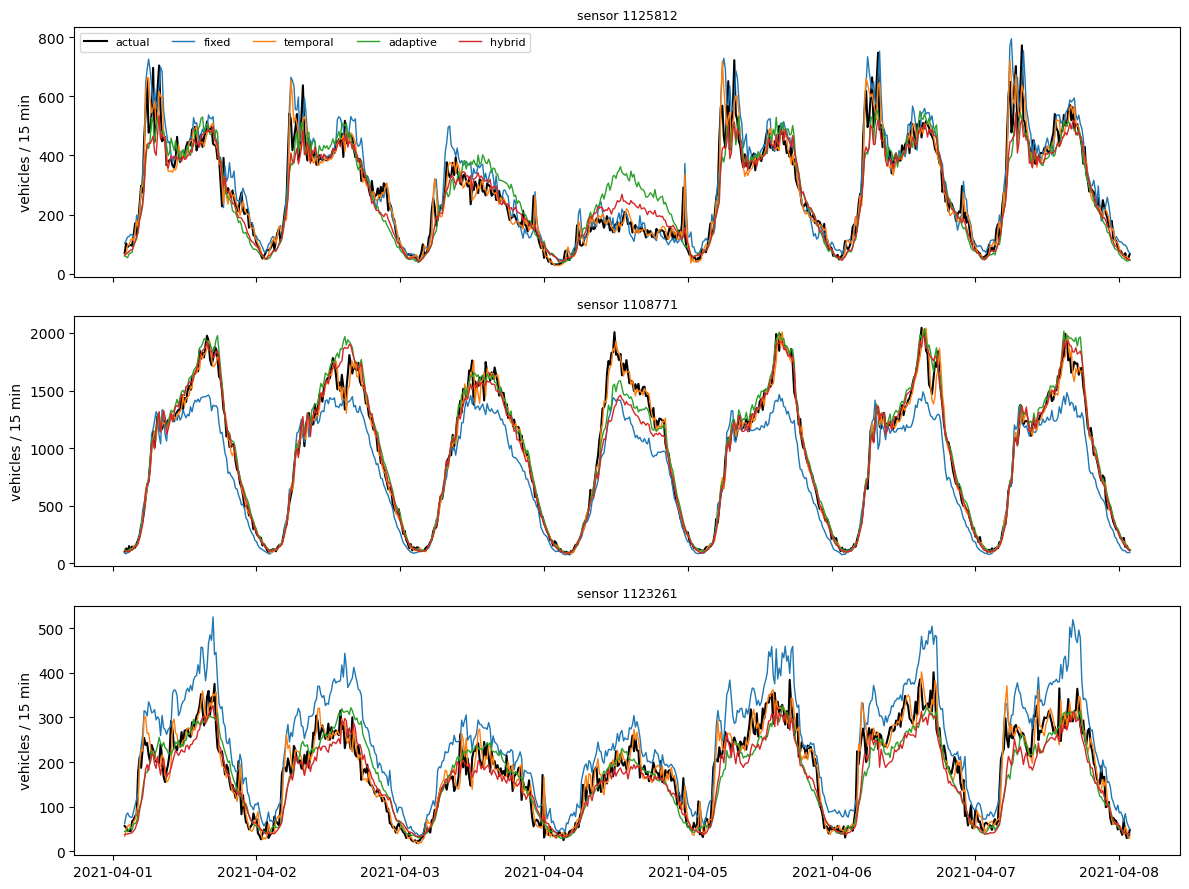

In [ ]:
import matplotlib.pyplot as plt
plot_ids = [sd_ids.index(str(s)) for s in chosen]          
n = 672                                                    

def predict(model, sp, n, bs=256):
    out = []
    with torch.no_grad():
        for i in range(0, n, bs):
            x, _, _ = sp.batch(torch.arange(i, min(i+bs, n), device=DEV))
            out.append(model(x)[:, 0, :].cpu())           
    return (torch.cat(out).numpy() * sd + mu)

preds = {k: predict(load_model(k), S["test"], n)[:, plot_ids] for k in results}
t0_ = pd.Timestamp(splits["test"][0])
ts = X15.loc[splits["test"][0]:splits["test"][1]].index[H:H+n]   
actual = X15.loc[splits["test"][0]:splits["test"][1]].values[H:H+n][:, plot_ids]   

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for j, a in enumerate(ax):
    a.plot(ts, actual[:, j], "k", lw=1.5, label="actual")
    for k, p in preds.items(): a.plot(ts, p[:, j], lw=1, label=k)
    a.set_title(f"sensor {chosen[j]}", fontsize=9); a.set_ylabel("vehicles / 15 min")
ax[0].legend(ncol=5, fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/q6a_pred.png", dpi=150); plt.show()

rows with < 20 positive scores: 0.0% | median positive per row: 359.0
learned edges: 14219
overlap with road graph: 5.9% (chance = 3.4%)
mean distance (km): learned 25.2 | road graph 2.3 | random pairs 27.1
share of learned edges pointing at all-NaN sensors: 0.041
same freeway share, learned: 0.134 | road graph: 0.223


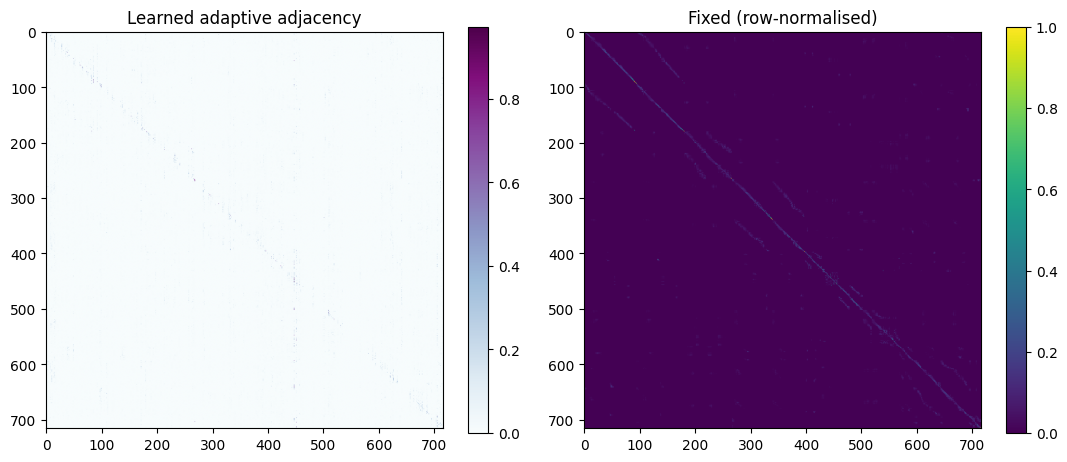

In [ ]:
ad = load_model("adaptive")
with torch.no_grad():
    Sc = ad.scores().cpu().numpy(); Al = ad.adaptive().cpu().numpy()
K = 20
pos = (Sc > 0).sum(1)
print(f"rows with < {K} positive scores: {(pos < K).mean():.1%} | median positive per row: {np.median(pos)}")

top = np.argsort(-Sc, 1)[:, :K]
good = (np.take_along_axis(Sc, top, 1) > 0)                 
ii = np.repeat(np.arange(716)[:, None], K, 1)
m_ = good & (top != ii)                                     
src, dst = ii[m_], top[m_]                                  

nzA = A != 0; off = nzA & ~np.eye(716, dtype=bool)
dens = off.sum() / (716 * 715)
print("learned edges:", len(src))
print(f"overlap with road graph: {nzA[src, dst].mean():.1%} (chance = {dens:.1%})")

lat, lng = np.radians(meta_sd["Lat"].values), np.radians(meta_sd["Lng"].values)
def km(i, j):
    a = np.sin((lat[j]-lat[i])/2)**2 + np.cos(lat[i])*np.cos(lat[j])*np.sin((lng[j]-lng[i])/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
ri, rj = np.where(off); rng = np.random.default_rng(SEED)
a_, b_ = rng.integers(0, 716, 50000), rng.integers(0, 716, 50000); ok = a_ != b_
print(f"mean distance (km): learned {km(src, dst).mean():.1f} | road graph {km(ri, rj).mean():.1f} | random pairs {km(a_[ok], b_[ok]).mean():.1f}")

dead = np.where(X15.loc[splits['train'][0]:splits['train'][1]].isna().all().values)[0]
print("share of learned edges pointing at all-NaN sensors:", np.isin(dst, dead).mean().round(3))
print("same freeway share, learned:", (meta_sd["Fwy"].values[src] == meta_sd["Fwy"].values[dst]).mean().round(3),
      "| road graph:", (meta_sd["Fwy"].values[ri] == meta_sd["Fwy"].values[rj]).mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
im = ax[0].imshow(Al, cmap="BuPu"); ax[0].set_title("Learned adaptive adjacency"); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(A_fixed.cpu().numpy(), cmap="viridis"); ax[1].set_title("Fixed (row-normalised)"); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.savefig(f"{OUT}/q6b_adj.png", dpi=150); plt.show()